In [71]:
import pandas as pd
import matplotlib.pyplot as plt
import importlib
import numpy as  np

In [72]:
import dashboard as ds
importlib.reload(ds)

<module 'dashboard' from 'd:\\Universidad\\TPE - Ciencia de datos\\dashboard.py'>

In [73]:
import utils
importlib.reload(utils)

<module 'utils' from 'd:\\Universidad\\TPE - Ciencia de datos\\utils.py'>

In [74]:
data_path = 'results.csv'
df = pd.read_csv(data_path, low_memory=False)

meta_path = 'schema.csv'
metadatos = pd.read_csv(meta_path)

<h1 style="color: orange;">Analisis Exploratorio

<h3 style="color: violet;">Distribucion de variables

In [75]:
def maping_and_add(col, values_change, min, dash, multiple=False):
    if not multiple:
        values = df[col].value_counts().index.to_list()
    else:
        values = (
            df[col]
            .dropna()
            .str.split(';')
            .explode()
            .str.strip()
            .value_counts()
        ).index.to_list()
    mapeo = {}
    for i, val in enumerate(values):
        if i == len(values_change): break
        mapeo[val] = values_change[i]
    dash.add.bar(df, col, min=min, cut=mapeo, multiple_r=multiple, max_cat=len(values_change))

<h4><u>Demografía y Perfil Laboral

In [76]:
def histEs(bins=5):
    def draw(ax):
        comp = df['CompTotal'].dropna()
        limite = comp.quantile(0.85)

        comp[comp <= limite].hist(
            bins=bins,
            edgecolor='black',
            ax=ax
        )

        ax.set_title('CompTotal:85%')
        ax.set_xlabel('')
        ax.grid(False)
        ax.tick_params(axis="x", rotation=45)

    return ds.Chart(draw=draw)

In [77]:
dash1 = ds.Dashboard(columns=4, figsize=(20, 4))

In [78]:
maping_and_add('MainBranch', [1, 2, 3, 4, 5, 6], min=2000, dash=dash1)
maping_and_add('EdLevel', ['Bd', 'Md', 'CU', 'Ss', 'Pd', 'Ad', 'Othr', 'Ps'], min=2000, dash=dash1)
maping_and_add('OrgSize', ['20-99', '100-499', '<20', '>10k', '1k-5k', '500-1k', 'Me', '5k-10k', 'DK'], min=2400, dash=dash1)
maping_and_add('DevType', ['Fs', 'Be', 'Stud', 'Arch', 'Fe', 'd_e'], min=2400, dash=dash1)
maping_and_add('RemoteWork', ['Remote', 'H_p', 'Person', 'H_r', 'Choice'], min=2400, dash=dash1)
maping_and_add('NewRole', ['No', 'con_1', 'con_2', 'Yes_v', 'Yes_i'], min=2400, dash=dash1)

In [79]:
#this
df['Employment'] = df['Employment'].replace('Independent contractor, freelancer, or self-employed', 'Independent')
dash1.add.bar(df, "Employment", min=1000, cut=6)

In [ ]:
dash1.add.bar(df, "Country", min=1000, cut=3)
dash1.add.bar(df, "Age", min=2000, cut=' ')
dash1.add.bar(df, "Currency", min=1000, cut=3)
dash1.add.bar(df, "Industry", min=1500, cut=3)
dash1.add.bar(df, "ICorPM", min=1500, cut=5)
dash1.addChart(histEs(bins=5))
columnas1 = [
    'MainBranch',
    'Age',
    'Country',
    'Currency',
    'EdLevel',
    'Employment',
    'EmploymentAddl',
    'Industry',
    'OrgSize',
    'DevType',
    'ICorPM',
    'RemoteWork',
    'JobSat',
    'NewRole'
]
dash1.add.multiple_hist(df, columnas1, bins=10)

dash1.show()

<h4><u>Experencia y aprendizaje

In [81]:
dash2 = ds.Dashboard(columns=4, figsize=(20, 4))

In [82]:
columnas2 = [
    'WorkExp',
    'YearsCode',
    'LearnCodeChoose',
    'LearnCode',
    'LearnCodeAI',
    'AILearnHow',
]
dash2.add.multiple_hist(df, columnas2, bins=12)
maping_and_add('LearnCodeChoose', ['yes - master', 'no - master', 'yes = junr'], 0, dash2)
#maping_and_add('LearnCode', [], 0, dash2)
maping_and_add('LearnCodeAI', ['IA_Prof', 'IA_Pers', 'NoIA_Pers', 'No_learn', 'NoIA_Prof'], 0, dash2)
#maping_and_add('AILearnHow', [], 0, dash2)

In [ ]:
dash2.show()

<h4><u>Stack Tecnológico y Herramientas

In [85]:
dash3 = ds.Dashboard(columns=4, figsize=(20, 4))

In [86]:
def all_columns(df, start, values_change=[], min=0, ignored=None):
    sub = df.loc[:, df.columns.str.startswith(start)]
    for i in sub:
        if i != start + 'Choice' and (not ignored or i != start + ignored):
            maping_and_add(i, values_change, min, dash3, multiple=True)

In [87]:
columnas3 = [
    'LanguageChoice',
    'LanguageHaveWorkedWith',
    'LanguageWantToWorkWith',
    'LanguageAdmired',
    'DatabaseChoice',
    'DatabaseHaveWorkedWith',
    'DatabaseWantToWorkWith',
    'DatabaseAdmired',
    'PlatformChoice',
    'PlatformHaveWorkedWith',
    'PlatformWantToWorkWith',
    'PlatformAdmired',
    'WebframeChoice',
    'WebframeHaveWorkedWith',
    'WebframeWantToWorkWith',
    'WebframeAdmired',
    'DevEnvsChoice',
    'DevEnvsHaveWorkedWith',
    'DevEnvsWantToWorkWith',
    'DevEnvsAdmired',
    'OpSysPersonal use',
    'OpSysProfessional use',
    'OfficeStackAsyncHaveWorkedWith',
    'OfficeStackAsyncWantToWorkWith',
    'OfficeStackAsyncAdmired',
    'CommPlatformHaveWorkedWith',
    'CommPlatformWantToWorkWith',
    'CommPlatformAdmired',
    'AIModelsChoice',
    'AIModelsHaveWorkedWith',
    'AIModelsWantToWorkWith',
    'AIModelsAdmired',
]

In [88]:
dash3.add.bar(df, 'LanguageChoice', 0)
all_columns(df, 'Language', ['Js', 'HT/CS', 'SQL', 'Py', 'Sh', 'Ts'], 10000, 'Admired')
maping_and_add('LanguageAdmired', ['Js', 'HT/CS', 'SQL', 'Py', 'Sh', 'Ts'], 5000, dash3, multiple=True)

In [89]:
dash3.add.bar(df, 'DatabaseChoice', 0)
maping_and_add('DatabaseHaveWorkedWith', ['Postgres', 'MySQL', 'SQLite', 'MSSQL', 'Redis'], 7000, dash3, multiple=True)
maping_and_add('DatabaseWantToWorkWith', ['Postgres', 'MySQL', 'SQLite', 'MSSQL', 'Redis'], 3000, dash3, multiple=True)
maping_and_add('DatabaseAdmired', ['Postgres', 'MySQL', 'SQLite', 'MSSQL', 'Redis'], 3000, dash3, multiple=True)

In [90]:
dash3.add.bar(df, 'PlatformChoice', 0)
maping_and_add('PlatformHaveWorkedWith', ['Docker', 'npm', 'AWS', 'Pip', 'K8s'], 6900, dash3, multiple=True)
maping_and_add('PlatformWantToWorkWith', ['Docker', 'npm', 'AWS', 'Pip', 'K8s'], 3000, dash3, multiple=True)
maping_and_add('PlatformAdmired', ['Docker', 'npm', 'AWS', 'Pip', 'K8s'], 3000, dash3, multiple=True)

In [91]:
dash3.add.bar(df, 'WebframeChoice', 0)
maping_and_add('WebframeHaveWorkedWith', ['Docker', 'npm', 'AWS', 'Pip', 'K8s'], 3000, dash3, multiple=True)
maping_and_add('WebframeWantToWorkWith', ['Docker', 'npm', 'AWS', 'Pip', 'K8s'], 3000, dash3, multiple=True)
maping_and_add('WebframeAdmired', ['Docker', 'npm', 'AWS', 'Pip', 'K8s'], 1000, dash3, multiple=True)

In [92]:
dash3.add.bar(df, 'DevEnvsChoice', 0)
maping_and_add('DevEnvsHaveWorkedWith', ['VSC', 'VS', 'Not++', 'IntJ', 'Vim', 'Curs'], 3000, dash3, multiple=True)
maping_and_add('DevEnvsWantToWorkWith', ['VSC', 'VS', 'Not++', 'IntJ', 'Vim', 'Curs'], 3000, dash3, multiple=True)
maping_and_add('DevEnvsAdmired', ['VSC', 'VS', 'Not++', 'IntJ', 'Vim', 'Curs'], 1000, dash3, multiple=True)

In [93]:
maping_and_add('OfficeStackAsyncHaveWorkedWith', ['GH', 'Jira', 'GL', 'MD', 'Confl'], 3000, dash3, multiple=True)
maping_and_add('OfficeStackAsyncWantToWorkWith', ['GH', 'Jira', 'GL', 'MD', 'Confl'], 3000, dash3, multiple=True)
maping_and_add('OfficeStackAsyncAdmired', ['GH', 'Jira', 'GL', 'MD', 'Confl'], 1000, dash3, multiple=True)

In [94]:
maping_and_add('CommPlatformHaveWorkedWith', ['SO', 'GH', 'YT', 'Redd', 'SE', 'Disc', 'Link'], 3000, dash3, multiple=True)
maping_and_add('CommPlatformWantToWorkWith', ['SO', 'GH', 'YT', 'Redd', 'SE', 'Disc', 'Link'], 3000, dash3, multiple=True)
maping_and_add('CommPlatformAdmired', ['SO', 'GH', 'YT', 'Redd', 'SE', 'Disc', 'Link'], 1000, dash3, multiple=True)

In [95]:
dash3.add.bar(df, 'AIModelsChoice', 0)
maping_and_add('AIModelsHaveWorkedWith', ['GPT', 'CS', 'GF', 'OAI-R', 'OAI-I', 'GP', 'Deep R'], 3000, dash3, multiple=True)
maping_and_add('AIModelsWantToWorkWith', ['GPT', 'CS', 'GF', 'OAI-R', 'OAI-I', 'GP', 'Deep R'], 3000, dash3, multiple=True)
maping_and_add('AIModelsAdmired', ['GPT', 'CS', 'GF', 'OAI-R', 'OAI-I', 'GP', 'Deep R'], 1000, dash3, multiple=True)

In [273]:
del dash3.charts[-4:]

In [ ]:
dash3.show()

<h3 style="color: violet;">Analisis de Outliers de variables numericas

<h4><u>CompTotal

Recordamos que un valor outlier es aquel que se encuentra por debajo de Q1 - 1.5 x IQR o por encima de Q3 + 1.5 x IQR

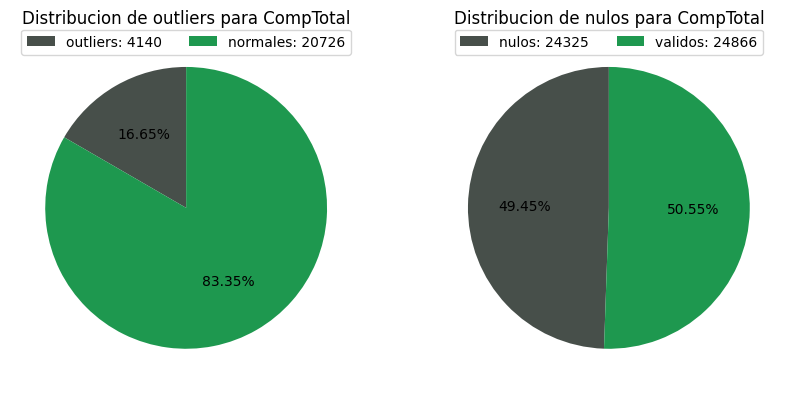

In [97]:
utils.graficar_nulos_outliers(df, 'CompTotal')

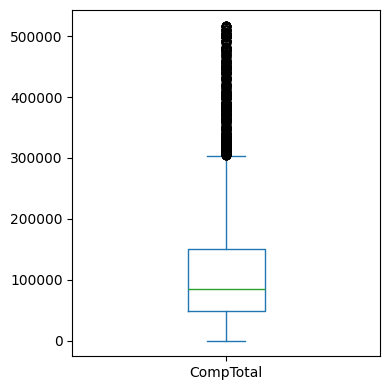

In [98]:
_, norm = utils.get_rangos(df, 'CompTotal')
plt.figure(figsize=(4, 4))
ax = norm['CompTotal'].plot(kind='box')

ax.set_xlim(0.7, 1.3)
plt.tight_layout()
plt.show()

<h4><u>WorkExp

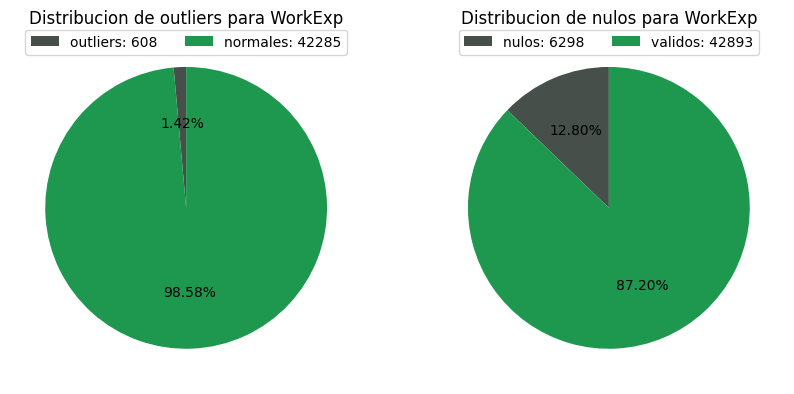

In [99]:
utils.graficar_nulos_outliers(df, 'WorkExp')

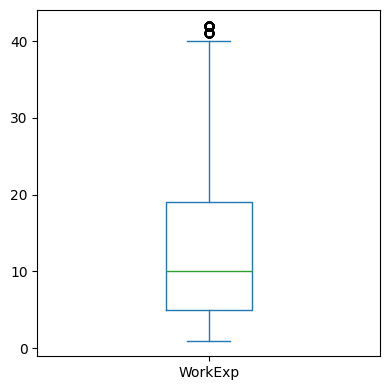

In [100]:
_, norm = utils.get_rangos(df, 'WorkExp')
plt.figure(figsize=(4, 4))
ax = norm['WorkExp'].plot(kind='box')

ax.set_xlim(0.7, 1.3)
plt.tight_layout()
plt.show()

<h4><u>yearCode

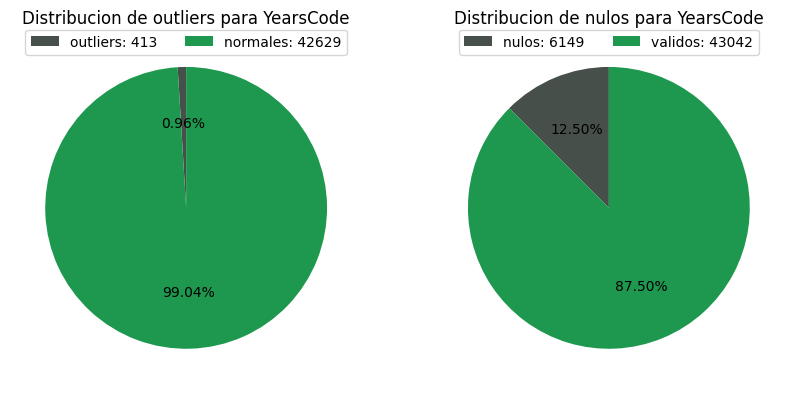

In [101]:
utils.graficar_nulos_outliers(df, 'YearsCode')

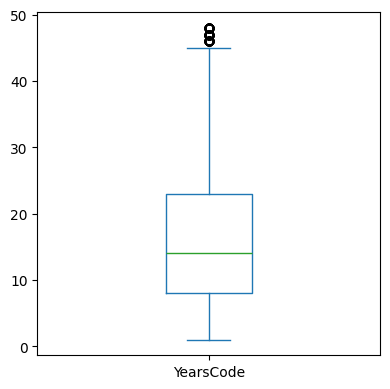

In [102]:
_, norm = utils.get_rangos(df, 'YearsCode')
plt.figure(figsize=(4, 4))
ax = norm['YearsCode'].plot(kind='box')

ax.set_xlim(0.7, 1.3)
plt.tight_layout()
plt.show()

<h1 style="color: orange;">Limpieza de datos

<h3 style="color: violet;">Reduccion de variables a considerar durante el analisis de datos

In [103]:
clean_metadatos = metadatos

<h4><u>Variables de respuesta libre

Analizando el dataset de metadatos, vemos que son aquellas que tienen como tipo de respuesta admitida ('type'):
- TE (Text Entry)
- RO (Ranking Order) con ('sub') = TEXT

In [104]:
columns_save = [
    'WorkExp',
    'YearsCode',
    'ToolCountWork',
    'ToolCountPersonal',
    'CompTotal'
]
var_free = metadatos[(metadatos['type'] == 'TE') | (metadatos['sub'].str.contains('Text'))]
var_free = var_free[~var_free['qname'].isin(columns_save)] #salvamos aquellas que necesitamos
clean_metadatos.drop(var_free.index)
var_free[['qname', 'question', 'type', 'sub']].head(6)

,qname,question,type,sub
10,TechEndorse_13_TEXT,What attracts you to a technology or causes yo...,RO,Other (please specify): - Text
21,TechOppose_15_TEXT,What would turn you off or cause you to reject...,RO,Other (please specify): - Text
37,JobSatPoints_15_TEXT,Rank the following attributes of your current ...,RO,Other (please specify): - Text
48,SO_Actions_15_TEXT,"When visiting Stack Overflow, which following ...",RO,Other (write in): - Text
77,LanguagesHaveEntry,Was the programming language you use not liste...,TE,NaN
78,LanguagesWantEntry,Was the programming language you want to use n...,TE,NaN


Ademas, realizamos un promedio de porcentajes de valores nulos entre todas las columnas que descartamos y observamos que, en  promedio, el 84% de los valores de estas eran nulos. Observado tambien en el grafico de torta

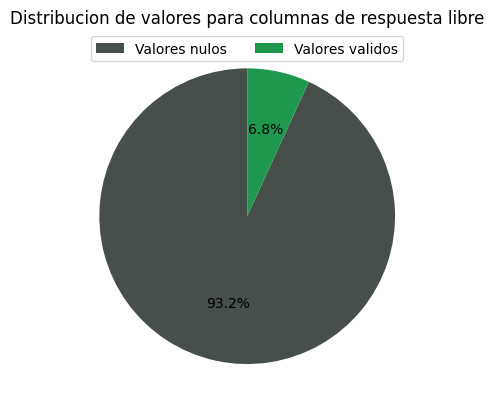

In [ ]:
utils.graficar_nulos(
    df,
    var_free['qname'].tolist(),
    labels=['Valores nulos', 'Valores validos'],
    title='Distribucion de valores para columnas de respuesta libre',
    colors=["#474f4a", '#1e984f']
)

In [106]:
j = percentage_null = 0
cant_null = cant_not_null = 0
for i in var_free['qname']:
    cant_null += df[i].isna().sum()
    cant_not_null += df[i].notna().sum()
    percentage_null += df[i].isna().mean()
    j += 1

percentage_null /= j
print(f"Promedio: {percentage_null} - Cantidad nulos: {cant_null} - Cantidad no nulos: {cant_not_null} - Total: {cant_null + cant_not_null}")

Promedio: 0.93152710861743 - Cantidad nulos: 1283037 - Cantidad no nulos: 94311 - Total: 1377348


In [107]:
df = df.drop(columns=var_free['qname'].to_list(), errors="ignore")

<h4><u>Variables asociadas al uso de StackOverflow

Analizando el dataset de metadatos, vemos que son aquellas que comienzan con 'SO' en el nombre de variable

In [109]:
var_SO = metadatos[metadatos['qname'].str.startswith('SO')]
clean_metadatos.drop(var_SO.index)
var_SO[['qname', 'question']].head(3)

,qname,question
38,SO_Actions_1,"When visiting Stack Overflow, which following ..."
39,SO_Actions_16,"When visiting Stack Overflow, which following ..."
40,SO_Actions_3,"When visiting Stack Overflow, which following ..."


In [110]:
df = df.drop(columns=var_SO['qname'].to_list(), errors="ignore")

In [58]:
df = df.drop_duplicates()

In [64]:
df = df.drop(columns='ResponseId')